# Using the SCN MAE pretrained encoder

This notebook shows how to:

1. load the MAE ViT-B / ViT-L encoder pretrained on (enhanced) SCN images,
2. run it on images and get the **latent representations** (CLS token, patch tokens, pooled embedding, intermediate layers),
3. train a **classification head** on top of it, either
   * a quick **linear probe on cached embeddings** (seconds, good for trying latent-space ideas), or
   * the full **fine-tuning recipe** used in our downstream experiments (`main_downstream_merged.py` + `run_all_downstream_merged.sbatch`),
4. evaluate on the test set per image and per tape-strip sample,
5. plug **your own latent-space module** in between the encoder and the head.

Everything the notebook needs is in `mae_encoder.py`, which sits next to it. The model is plain PyTorch, and timm is only used for the training augmentations and Mixup/CutMix.

**Requirements:** `pip install torch torchvision timm scikit-learn pandas matplotlib`. It was tested with torch 2.6 and timm 1.0, on one GPU.

## 1. Setup and configuration
Edit the paths in the next cell to match your machine.

In [1]:
import os, json, time, math, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

import mae_encoder as me   # helper module in this folder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch 2.6.0+cu124 | device: cuda | Quadro RTX 8000


In [2]:
# ---------------------------------------------------------------- paths ---
DATA_PATH = Path("/storage/jenhung/data/SCN_finetune/enhanced/ad_cls")   # contains train/ val/ test/ (+ metadata_test.csv)

CHECKPOINTS = {
    "B": "/storage/jenhung/results/scn/pretrained/mae/mae_pretrain_B_mask50_enhanced/checkpoint-799.pth",
    "L": "/storage/jenhung/results/scn/pretrained/mae/mae_pretrain_L_mask50_enhanced/checkpoint-799.pth",
}
MODEL_SIZE = "B"            # "B" (86M params) or "L" (304M params)
OUTPUT_DIR = Path("outputs") / f"{DATA_PATH.name}_MAE-{MODEL_SIZE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# The checkpoints were pretrained on *enhanced* SCN images; use the matching
# normalisation (me.ORIGINAL_MEAN / ORIGINAL_STD for the original images).
MEAN, STD = me.ENHANCED_MEAN, me.ENHANCED_STD

# ------------------------------------------------- training hyperparameters ---
# Same values as run_all_downstream_merged.sbatch.
TRAINING_MODE  = "finetune"     # "finetune" (whole network) or "linprobe" (frozen encoder)
TRAIN_SAMPLING = "ordinary"     # "ordinary" or "class_balanced"
INPUT_SIZE     = 224
BATCH_SIZE     = 32             # micro-batch on the GPU
ACCUM_ITER     = 8              # gradient accumulation -> effective batch 256
BLR            = 1e-3           # base lr; actual lr = BLR * eff_batch / 256
MIN_LR         = 1e-6
EPOCHS         = 100
WARMUP_EPOCHS  = 5
SMOOTHING      = 0.1
SEED           = 0
NUM_WORKERS    = min(8, os.cpu_count() or 1)

if TRAINING_MODE == "finetune":
    WEIGHT_DECAY, LAYER_DECAY, MIXUP, CUTMIX = 0.05, 0.75, 0.8, 1.0
    DROP_PATH = 0.2 if MODEL_SIZE == "L" else 0.1
else:  # linprobe
    WEIGHT_DECAY, LAYER_DECAY, MIXUP, CUTMIX = 0.0, 1.0, 0.0, 0.0   # LAYER_DECAY 1.0 = off
    DROP_PATH = 0.0

# If you run out of GPU memory, keep BATCH_SIZE * ACCUM_ITER = 256,
# e.g. BATCH_SIZE, ACCUM_ITER = 16, 16. Measured peak memory when fine-tuning:
# ViT-L about 9.5 GB at batch 32 and 7 GB at 16. ViT-B needs less.
EFF_BATCH = BATCH_SIZE * ACCUM_ITER
LR = BLR * EFF_BATCH / 256

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
print(f"mode={TRAINING_MODE}  model=MAE-{MODEL_SIZE}  eff_batch={EFF_BATCH}  lr={LR:.2e}  drop_path={DROP_PATH}")

mode=finetune  model=MAE-B  eff_batch=256  lr=1.00e-03  drop_path=0.1


## 2. Data

Each task folder is in `ImageFolder` format: `train/<class>/*.png`, `val/<class>/*.png` and `test/<class>/*.png`. For `ad_cls` the classes are the four AD groups G1–G4. `metadata_test.csv` links each test image to its tape-strip sample (`cohort` + `folder`) and participant, and section 7 uses it.

In [3]:
eval_tf  = me.build_transform(False, INPUT_SIZE, MEAN, STD)
train_tf = me.build_transform(True,  INPUT_SIZE, MEAN, STD)   # RandAugment + RandomErasing (as in our runs)

ds_train = me.build_dataset(DATA_PATH, "train", train_tf)
ds_val   = me.build_dataset(DATA_PATH, "val",   eval_tf)
ds_test  = me.build_dataset(DATA_PATH, "test",  eval_tf)

CLASSES = ds_train.classes
NUM_CLASSES = len(CLASSES)
assert ds_val.classes == CLASSES == ds_test.classes
for name, ds in [("train", ds_train), ("val", ds_val), ("test", ds_test)]:
    print(f"{name:5s} n={len(ds):5d}  per class:", dict(zip(CLASSES, np.bincount(ds.targets).tolist())))

train n= 1661  per class: {'G1': 475, 'G2': 480, 'G3': 466, 'G4': 240}
val   n=  140  per class: {'G1': 40, 'G2': 40, 'G3': 40, 'G4': 20}
test  n=  283  per class: {'G1': 80, 'G2': 80, 'G3': 83, 'G4': 40}


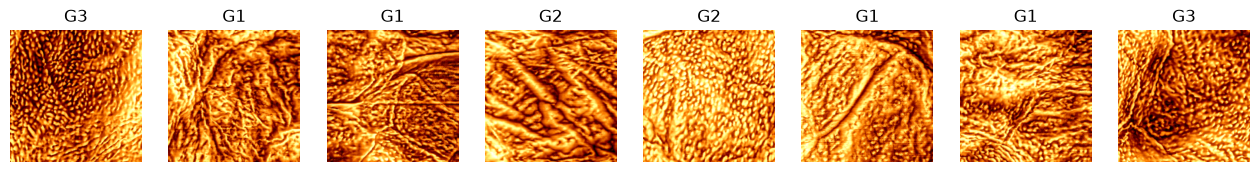

In [4]:
# Look at a few images (undo the normalisation for display).
def show(t):
    img = t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    return img.clip(0, 1)

rng = np.random.default_rng(0)
idx = rng.choice(len(ds_val), 8, replace=False)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, i in zip(axes, idx):
    x, y = ds_val[i]
    ax.imshow(show(x)); ax.set_title(CLASSES[y]); ax.axis("off")
plt.show()

## 3. Load the pretrained encoder and inspect its outputs

The MAE checkpoint holds the encoder, the decoder and the optimizer state. `load_mae_encoder` keeps only the encoder.

For a 224×224 image, `encoder(x)` returns tokens of shape `(B, 1 + 196, D)`:

| index | content |
|---|---|
| `tokens[:, 0]` | CLS token |
| `tokens[:, 1:]` | 196 patch tokens, one per 16×16 patch, row-major on a 14×14 grid |

`D` is 768 for ViT-B and 1024 for ViT-L. No final norm is applied. `encoder.norm` is the pretrained final LayerNorm if you want it.

Two common pooled latents:
* **avg**: mean of the patch tokens. Our downstream runs use this (`--global_pool`), followed by a LayerNorm.
* **cls**: the CLS token after `encoder.norm`.

`encoder(x, return_layers=[...])` returns the tokens after any blocks you choose, for multi-layer features.

In [5]:
encoder = me.load_mae_encoder(CHECKPOINTS[MODEL_SIZE], size=MODEL_SIZE, img_size=INPUT_SIZE).to(device).eval()

x = torch.stack([ds_val[i][0] for i in range(4)]).to(device)
with torch.no_grad():
    tokens = encoder(x)                                    # (B, 197, D)
    cls_latent = encoder.norm(tokens)[:, 0]                # (B, D)
    avg_latent = tokens[:, 1:].mean(1)                     # (B, D)
    grid = tokens[:, 1:].reshape(x.shape[0], 14, 14, -1)   # spatial map (B, 14, 14, D)
    mid_layers = encoder(x, return_layers=[3, 7, -1])      # list of (B, 197, D)

print("tokens     ", tuple(tokens.shape))
print("cls latent ", tuple(cls_latent.shape))
print("avg latent ", tuple(avg_latent.shape))
print("patch grid ", tuple(grid.shape))
print("layers     ", [tuple(t.shape) for t in mid_layers])

Loaded MAE ViT-B encoder (85.8M params, epoch 799) from /storage/jenhung/results/scn/pretrained/mae/mae_pretrain_B_mask50_enhanced/checkpoint-799.pth: <All keys matched successfully>


tokens      (4, 197, 768)
cls latent  (4, 768)
avg latent  (4, 768)
patch grid  (4, 14, 14, 768)
layers      [(4, 197, 768), (4, 197, 768), (4, 197, 768)]


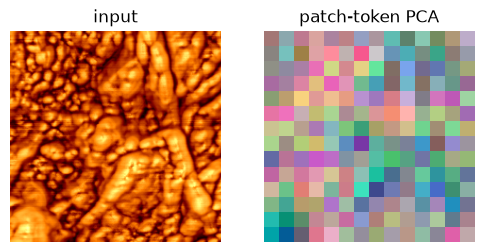

In [6]:
# Example: what do patch tokens encode? Project the 196 patch tokens of one image
# onto their first 3 principal components and show them as an RGB map.
with torch.no_grad():
    p = encoder.norm(encoder(x[:1]))[0, 1:].float().cpu()      # (196, D)
p = p - p.mean(0)
_, _, V = torch.pca_lowrank(p, q=3)
rgb = (p @ V[:, :3]).reshape(14, 14, 3)
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(show(x[0].cpu())); ax[0].set_title("input"); ax[0].axis("off")
ax[1].imshow(rgb.numpy()); ax[1].set_title("patch-token PCA"); ax[1].axis("off")
plt.show()

## 4. Extract frozen latents for the whole dataset

With the encoder frozen, you can compute the embeddings once and reuse them. That makes it cheap to try latent-space ideas such as projections, clustering or kNN without touching the encoder. The cell saves CLS and avg latents for every split to `latents.npz`.

All patch tokens for the whole dataset would be large (about 1.6 GB per split for ViT-B in fp32). If you need them, keep only the layers or tokens you use, or store them as fp16.

In [7]:
@torch.no_grad()
def extract_latents(encoder, dataset, batch_size=64):
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False,
                                         num_workers=NUM_WORKERS, pin_memory=True)
    out = {"cls": [], "avg": [], "y": []}
    encoder.eval()
    for xb, yb in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            t = encoder(xb.to(device, non_blocking=True))
        t = t.float()
        out["cls"].append(encoder.norm(t)[:, 0].cpu())
        out["avg"].append(t[:, 1:].mean(1).cpu())
        out["y"].append(yb)
    return {k: torch.cat(v).numpy() for k, v in out.items()}

ds_train_eval = me.build_dataset(DATA_PATH, "train", eval_tf)   # no augmentation for feature extraction
latents = {split: extract_latents(encoder, ds)
           for split, ds in [("train", ds_train_eval), ("val", ds_val), ("test", ds_test)]}

np.savez(OUTPUT_DIR / "latents.npz",
         **{f"{s}_{k}": v for s, d in latents.items() for k, v in d.items()},
         classes=np.array(CLASSES))
print({s: d["avg"].shape for s, d in latents.items()}, "->", OUTPUT_DIR / "latents.npz")

{'train': (1661, 768), 'val': (140, 768), 'test': (283, 768)} -> outputs/ad_cls_MAE-B/latents.npz


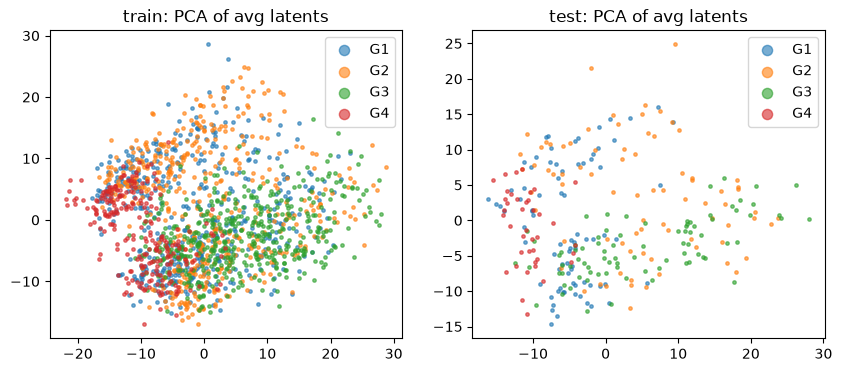

In [8]:
# 2-D PCA of the avg latents, coloured by class
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(latents["train"]["avg"])
pca = PCA(2).fit(scaler.transform(latents["train"]["avg"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, split in zip(axes, ["train", "test"]):
    z = pca.transform(scaler.transform(latents[split]["avg"]))
    for c in range(NUM_CLASSES):
        m = latents[split]["y"] == c
        ax.scatter(z[m, 0], z[m, 1], s=6, alpha=0.6, label=CLASSES[c])
    ax.set_title(f"{split}: PCA of avg latents"); ax.legend(markerscale=3)
plt.show()

## 5. Baseline A: linear classifier on the cached latents

Logistic regression on the frozen embeddings takes seconds. Use it as the reference when you try a latent-space trick: transform the cached latents, refit, and compare.

This is not the same protocol as the `linprobe` runs in our sbatch file, which train the head with image augmentation. For that, set `TRAINING_MODE = "linprobe"` in section 6.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

results_lin = {}
for pool in ["avg", "cls"]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.1))
    clf.fit(latents["train"][pool], latents["train"]["y"])
    results_lin[pool] = {split: me.classification_metrics(latents[split]["y"], clf.predict_proba(latents[split][pool]))
                         for split in ["val", "test"]}

pd.DataFrame({(p, s): m for p, d in results_lin.items() for s, m in d.items()}).round(3)

avg           cls       
                     val   test    val   test
accuracy           0.557  0.537  0.586  0.527
balanced_accuracy  0.575  0.579  0.594  0.552
f1                 0.566  0.551  0.595  0.535
roc_auc            0.864  0.808  0.855  0.797
kappa              0.401  0.379  0.436  0.362
score              0.610  0.579  0.629  0.565

## 6. Baseline B: fine-tune the encoder with a classification head

`me.MAEClassifier` does: encoder → mean of patch tokens → LayerNorm → *(optional `latent_module`)* → `Linear(D, num_classes)`.

The training recipe matches `main_downstream_merged.py`:
* AdamW with **layer-wise lr decay** (0.75), weight decay 0.05, and no decay on norms, biases, `pos_embed` and `cls_token`
* lr = 1e-3 × 256/256, with a 5-epoch linear warmup and then cosine decay to 1e-6, updated every optimizer step
* micro-batch 32 × 8 gradient-accumulation steps, fp16 autocast with a GradScaler
* RandAugment, RandomErasing 0.25, **Mixup 0.8 / CutMix 1.0** with label smoothing 0.1, and drop-path 0.1 (B) or 0.2 (L)
* the checkpoint with the best **validation score** = (macro-F1 + macro-AUROC + Cohen's κ)/3 is kept

`TRAINING_MODE = "linprobe"` freezes the encoder and turns off Mixup, weight decay and layer decay. The LayerNorm and head are still trained.

Fine-tuning ViT-B for 100 epochs on `ad_cls` (about 1,700 training images) took about 15 minutes on a Quadro RTX 8000 (about 8 s per epoch). ViT-L takes about 3× longer (around 40 minutes). To check that everything runs, set `EPOCHS = 2` first.

In [10]:
from timm.data.mixup import Mixup
from timm.loss import SoftTargetCrossEntropy


def make_train_loader():
    if TRAIN_SAMPLING == "class_balanced":
        sampler = me.make_balanced_sampler(ds_train)
    else:
        sampler = torch.utils.data.RandomSampler(ds_train)
    return torch.utils.data.DataLoader(ds_train, sampler=sampler, batch_size=BATCH_SIZE,
                                       num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)


@torch.no_grad()
def predict(model, dataset, batch_size=64):
    # Return (probs, labels) for a dataset, without augmentation.
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False,
                                         num_workers=NUM_WORKERS, pin_memory=True)
    model.eval()
    probs, ys = [], []
    for xb, yb in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(xb.to(device, non_blocking=True))
        probs.append(logits.float().softmax(-1).cpu()); ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def train_classifier(model, run_name="finetune", epochs=EPOCHS):
    # Train `model` (an me.MAEClassifier) with the recipe above.
    # The best checkpoint by validation score goes to OUTPUT_DIR/<run_name>_best.pth.
    model = model.to(device)
    if TRAINING_MODE == "linprobe":
        me.freeze_encoder(model)

    param_groups = me.param_groups_lrd(model, WEIGHT_DECAY, LAYER_DECAY)
    optimizer = torch.optim.AdamW(param_groups, lr=LR)
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

    mixup_fn = None
    if MIXUP > 0 or CUTMIX > 0:
        mixup_fn = Mixup(mixup_alpha=MIXUP, cutmix_alpha=CUTMIX, prob=1.0, switch_prob=0.5,
                         mode="batch", label_smoothing=SMOOTHING, num_classes=NUM_CLASSES)
        criterion = SoftTargetCrossEntropy()
    else:
        criterion = nn.CrossEntropyLoss(label_smoothing=SMOOTHING)

    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    print(f"[{run_name}] trainable params: {n_train:.2f}M")

    loader = make_train_loader()
    best_score, best_epoch, history = -float("inf"), -1, []
    ckpt_path = OUTPUT_DIR / f"{run_name}_best.pth"

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        t0, losses = time.time(), []
        for it, (xb, yb) in enumerate(loader):
            if it % ACCUM_ITER == 0:
                lr_now = me.adjust_learning_rate(optimizer, it / len(loader) + epoch,
                                                 LR, MIN_LR, epochs, WARMUP_EPOCHS)
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            if mixup_fn is not None:
                xb, yb = mixup_fn(xb, yb)
            with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                loss = criterion(model(xb), yb)
            if not math.isfinite(loss.item()):
                raise RuntimeError(f"Loss is {loss.item()}")
            scaler.scale(loss / ACCUM_ITER).backward()
            if (it + 1) % ACCUM_ITER == 0:
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(set_to_none=True)
            losses.append(loss.item())

        probs, ys = predict(model, ds_val)
        val = me.classification_metrics(ys, probs)
        history.append({"epoch": epoch, "lr": lr_now, "train_loss": float(np.mean(losses)),
                        **{f"val_{k}": v for k, v in val.items()}})
        is_best = val["score"] > best_score
        if is_best:
            best_score, best_epoch = val["score"], epoch
            torch.save({"model": model.state_dict(), "epoch": epoch, "classes": CLASSES,
                        "model_size": MODEL_SIZE, "val": val}, ckpt_path)
        print(f"ep {epoch:3d}  lr {lr_now:.2e}  loss {np.mean(losses):.4f}  "
              f"val acc {val['accuracy']:.3f} f1 {val['f1']:.3f} auc {val['roc_auc']:.3f} "
              f"score {val['score']:.3f}{'  *' if is_best else ''}  ({time.time() - t0:.0f}s)")

    print(f"[{run_name}] best val score {best_score:.4f} at epoch {best_epoch} -> {ckpt_path}")
    pd.DataFrame(history).to_csv(OUTPUT_DIR / f"{run_name}_history.csv", index=False)
    return ckpt_path, pd.DataFrame(history)

In [11]:
seed_everything(SEED)
encoder = me.load_mae_encoder(CHECKPOINTS[MODEL_SIZE], size=MODEL_SIZE,
                              img_size=INPUT_SIZE, drop_path_rate=DROP_PATH)
model = me.MAEClassifier(encoder, NUM_CLASSES, pool="avg")

best_ckpt, history = train_classifier(model, run_name=TRAINING_MODE)

Loaded MAE ViT-B encoder (85.8M params, epoch 799) from /storage/jenhung/results/scn/pretrained/mae/mae_pretrain_B_mask50_enhanced/checkpoint-799.pth: <All keys matched successfully>
[finetune] trainable params: 85.80M


ep   0  lr 1.88e-04  loss 1.3772  val acc 0.286 f1 0.111 auc 0.670 score 0.260  *  (9s)


ep   1  lr 3.88e-04  loss 1.3666  val acc 0.286 f1 0.111 auc 0.750 score 0.287  *  (8s)


ep   2  lr 5.88e-04  loss 1.3487  val acc 0.386 f1 0.266 auc 0.691 score 0.366  *  (8s)


ep   3  lr 7.88e-04  loss 1.3173  val acc 0.421 f1 0.405 auc 0.725 score 0.449  *  (8s)


...

ep  95  lr 5.49e-06  loss 1.0519  val acc 0.693 f1 0.695 auc 0.884 score 0.721  (8s)


ep  96  lr 3.55e-06  loss 1.0826  val acc 0.693 f1 0.695 auc 0.884 score 0.721  (8s)


ep  97  lr 2.16e-06  loss 1.0871  val acc 0.700 f1 0.702 auc 0.884 score 0.727  (8s)


ep  98  lr 1.31e-06  loss 1.0592  val acc 0.700 f1 0.702 auc 0.884 score 0.727  (7s)


ep  99  lr 1.00e-06  loss 1.0707  val acc 0.700 f1 0.702 auc 0.884 score 0.727  (7s)
[finetune] best val score 0.7271 at epoch 80 -> outputs/ad_cls_MAE-B/finetune_best.pth


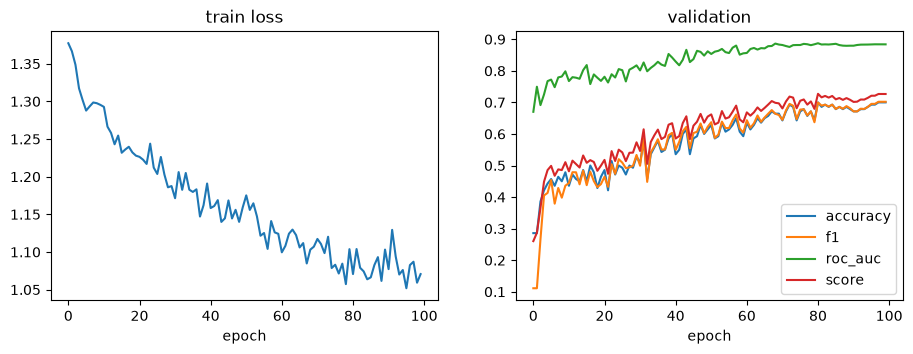

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.epoch, history.train_loss); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
for k in ["val_accuracy", "val_f1", "val_roc_auc", "val_score"]:
    ax[1].plot(history.epoch, history[k], label=k[4:])
ax[1].set_title("validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 7. Test evaluation of the best checkpoint

There are two levels:
* **image level**: one prediction per image.
* **sample level**: one prediction per tape-strip sample (`cohort` + `folder` in `metadata_test.csv`), made by averaging the class probabilities of its images (`mean_prob`, the same as our evaluator).

Our paper evaluator also reports participant-clustered bootstrap CIs, which this notebook leaves out.

loaded best epoch 80


283 test images -> 28 tape-strip samples


,image,sample
accuracy,0.597,0.821
balanced_accuracy,0.630,0.844
f1,0.613,0.843
roc_auc,0.862,0.934
kappa,0.457,0.757
score,0.644,0.845


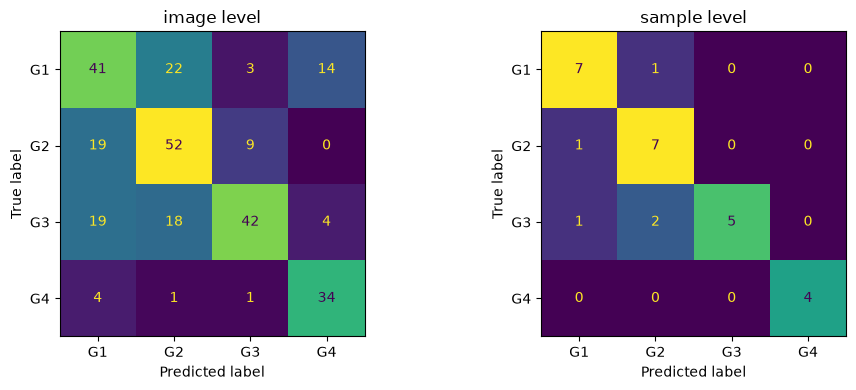

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

ckpt = torch.load(best_ckpt, map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["model"])
print("loaded best epoch", ckpt["epoch"])

test_probs, test_y = predict(model, ds_test)
image_metrics = me.classification_metrics(test_y, test_probs)

# ---- sample-level aggregation using the manifest
manifest_path = DATA_PATH / "metadata_test.csv"
sample_metrics = None
if manifest_path.exists():
    man = pd.read_csv(manifest_path)
    man["sample_id"] = man["cohort"].astype(str) + "__" + man["folder"].astype(str)
    rel = [Path(p).relative_to(DATA_PATH).as_posix() for p, _ in ds_test.samples]
    df = pd.DataFrame(test_probs, columns=CLASSES).assign(relative_path=rel, y=test_y)
    df = df.merge(man[["relative_path", "sample_id"]], on="relative_path", how="left")
    assert df.sample_id.notna().all(), "some test images are missing from metadata_test.csv"
    per_sample = df.groupby("sample_id").agg({**{c: "mean" for c in CLASSES}, "y": "first"})
    sample_metrics = me.classification_metrics(per_sample.y.values, per_sample[CLASSES].values)
    print(f"{len(df)} test images -> {len(per_sample)} tape-strip samples")

display(pd.DataFrame({"image": image_metrics, "sample": sample_metrics}).round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(test_y, test_probs.argmax(1), display_labels=CLASSES,
                                        ax=ax[0], colorbar=False); ax[0].set_title("image level")
if sample_metrics is not None:
    ConfusionMatrixDisplay.from_predictions(per_sample.y, per_sample[CLASSES].values.argmax(1),
                                            display_labels=CLASSES, ax=ax[1], colorbar=False)
    ax[1].set_title("sample level")
plt.tight_layout(); plt.show()

json.dump({"image": image_metrics, "sample": sample_metrics, "best_epoch": ckpt["epoch"]},
          open(OUTPUT_DIR / f"{TRAINING_MODE}_test_metrics.json", "w"), indent=2)

In [14]:
# After fine-tuning, the latents come from the fine-tuned encoder:
#   z = model.forward_latent(images)   -> (B, D), what the head sees
#   model.encoder(images)              -> all tokens of the fine-tuned encoder
with torch.no_grad():
    z = model.eval().forward_latent(x)
print(z.shape)

torch.Size([4, 768])


## 8. Plugging in your own latent-space trick

There are three places to hook in, from cheapest to most flexible:

1. **On cached latents (section 4).** Change `latents[...]["avg"]` (or the CLS or layer features), then refit the classifier from section 5. You never need to run the encoder again.
2. **`latent_module`.** Pass an `nn.Module` that maps the pooled latent `z` of shape `(B, D)` to `(B, D')`. It trains together with the head, and with the encoder when fine-tuning. Set `latent_dim=D'` if the size changes.
3. **Token level.** Subclass `MAEClassifier` and override `pool_tokens(tokens)`, where `tokens` has shape `(B, 1+N, D)`. Examples are attention pooling, token selection or masking, or mixing layers via `self.encoder(x, return_layers=...)` in `forward_latent`.

Both examples below can go straight into `train_classifier(...)` from section 6.

In [15]:
# (2) Example latent module: Gaussian noise in latent space during training + a small projector.
class NoisyProjector(nn.Module):
    def __init__(self, dim, out_dim=256, noise_std=0.1):
        super().__init__()
        self.noise_std = noise_std
        self.proj = nn.Sequential(nn.Linear(dim, out_dim), nn.GELU())

    def forward(self, z):
        if self.training and self.noise_std > 0:
            z = z + self.noise_std * torch.randn_like(z)
        return self.proj(z)


# (3) Example token-level trick: learnable attention pooling over patch tokens.
class AttnPoolClassifier(me.MAEClassifier):
    def __init__(self, encoder, num_classes):
        super().__init__(encoder, num_classes, pool="avg")
        self.score = nn.Linear(encoder.embed_dim, 1)

    def pool_tokens(self, tokens):
        patches = tokens[:, 1:]                               # (B, N, D)
        w = self.score(patches).softmax(dim=1)                # (B, N, 1) weight per patch
        return self.fc_norm((w * patches).sum(dim=1))         # (B, D)


enc = me.load_mae_encoder(CHECKPOINTS[MODEL_SIZE], size=MODEL_SIZE, verbose=False)
m1 = me.MAEClassifier(enc, NUM_CLASSES, latent_module=NoisyProjector(enc.embed_dim), latent_dim=256).to(device)
m2 = AttnPoolClassifier(enc, NUM_CLASSES).to(device)
with torch.no_grad():
    print(m1(x).shape, m2(x).shape)

# To train one of them with the same recipe:
# ckpt_path, hist = train_classifier(m2, run_name="attnpool")

torch.Size([4, 4]) torch.Size([4, 4])


## Tips

* **Other tasks.** Point `DATA_PATH` at another task folder such as `gender_cls` or `uv_cls`. The number of classes is read from the folder.
* **ViT-L.** Set `MODEL_SIZE = "L"`. Fine-tuning at batch 32 peaked at about 9.5 GB of GPU memory (7 GB at batch 16). On a smaller GPU, use `BATCH_SIZE, ACCUM_ITER = 16, 16` or `8, 32`. Extracting frozen features needs under 4 GB.
* **Smaller checkpoint files.** `me.export_encoder_weights(src, "mae_B_encoder.pth")` writes an encoder-only file, about 4× smaller, and `load_mae_encoder` reads it the same way.
* **Reproducibility.** Results vary a little between runs even with a fixed seed, because of Mixup/CutMix and cuDNN. Compare tricks over a few seeds.
* **Leakage.** Pick hyperparameters and checkpoints on `val`, and look at `test` only at the end.